# Final evaluation of Mirage tactic classification

The TCN on shared clip features is the selected model, chosen by nested cross-validation (see the comparison notebook, 6.2). The final TCN and GRU are both shown on the test set side by side, as in the app; the test results do not change the choice.

In [1]:
# @title Load the saved results
import csv
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import HTML, Markdown, display

%matplotlib inline

ROOT = next(
    (p for p in (Path.cwd(), *Path.cwd().parents) if (p / "stratscout").is_dir() and (p / "AGENTS.md").is_file()),
    None,
)
if ROOT is None:
    raise RuntimeError("Open this notebook from the CV-DL repository or its notebooks folder.")
sys.path.insert(0, str(ROOT))
from stratscout.config import TACTIC_CLASSES  # noqa: E402
from stratscout.tactic_tcn import classification_metrics  # noqa: E402  (the scoring behind the TCN's saved test report)

# Every folder this notebook reads, listed once (Appendix A says how each was made).
RUNS = {
    "tcn_final": "runs/tactic-tcn-clipdata-final",  # final TCN: models, saved test report and test predictions
    "gru_final": "runs/tactic-gru-clipdata-final-20261121",  # final Compact pooled GRU: models and training report
    "gru_test": "runs/tactic-gru-clipdata-test-20261121",  # the GRU's one test run, with the TCN check
    "tcn_nested": "runs/tactic-tcn-clipdata-nested-20261120",  # nested cross-validation, TCN (training matches only)
    "gru_nested": "runs/tactic-clipdata-nested-20261120",  # nested cross-validation, Compact pooled GRU (gru/)
}
run = {key: ROOT / path for key, path in RUNS.items()}
missing = [path for key, path in RUNS.items() if not run[key].is_dir()]
if missing:
    raise FileNotFoundError("Run folders not found: " + ", ".join(missing) + " (see Appendix A)")

CLASSES = list(TACTIC_CLASSES)
KINDS = ["tcn", "gru"]
MODEL = {"tcn": "TCN", "gru": "Compact pooled GRU"}
SHORT = {"tcn": "TCN", "gru": "GRU"}
COLOURS = {"tcn": "#41ab5d", "gru": "#6a51a3"}
MATCH_NAMES = {
    "navi-falcons-mirage-cologne-major": "NaVi vs Falcons",
    "vitality-falcons-mirage-esl-pro-league-season-24": "Vitality vs Falcons",
    "spirit-falcons-mirage-cologne-major": "Spirit vs Falcons",
    "furia-falcons-mirage-cologne-major-2026": "Furia vs Falcons",
    "mouz-betboom-mirage-iem-bejing-2026": "MOUZ vs BetBoom",
    "aurora-vitality-mirage-esl-pro-league-season-24": "Aurora vs Vitality",
}
WORDS = {1: "one", 2: "two", 3: "three", 4: "four", 5: "five", 6: "six"}
FONT = "font-family: 'Segoe UI', Arial, sans-serif; font-size: 13px;"
TOLERANCE = 1e-9
ROUNDING = 1e-4 + 1e-9  # one step of the 4-decimal rounding in the prediction files
CHECKS = {}  # section -> checked claims, printed in Appendix A


def show_table(name, df, decimals=3):
    """Text columns left, number columns right; scores to three decimals; no index. `name`
    is the table's fixed HTML id, so rerunning the notebook leaves the saved output unchanged."""
    numbers = [c for c in df.columns if len(df) and all(isinstance(v, (int, float, np.number)) and not isinstance(v, bool) for v in df[c])]
    fmt_ = {c: (lambda v, d=decimals: f"{v:d}" if isinstance(v, (int, np.integer)) else f"{v:.{d}f}") for c in numbers}
    styles = [
        {"selector": "th", "props": FONT + " font-weight: 600; padding: 4px 10px; border-bottom: 1px solid #999;"},
        {"selector": "td", "props": FONT + " padding: 4px 10px;"},
    ]
    for i, column in enumerate(df.columns):
        styles.append({"selector": f"th.col_heading.col{i}", "props": f"text-align: {'right' if column in numbers else 'left'};"})
    styler = df.style.set_uuid(name).hide(axis="index").format(fmt_).set_table_styles(styles)
    text = [c for c in df.columns if c not in numbers]
    if text:
        styler = styler.set_properties(subset=text, **{"text-align": "left"})
    if numbers:
        styler = styler.set_properties(subset=numbers, **{"text-align": "right"})
    display(HTML(styler.to_html()))  # HTML only: the Styler's text form holds a memory address


def say(text):
    display(Markdown(text))


def claims(section, checks):
    """Each check is (claim, test). A claim that fails stops the notebook; the checked
    claims are listed in Appendix A."""
    for claim, holds in checks:
        if not holds():
            raise AssertionError(f"The text of section {section} no longer holds: {claim}")
    CHECKS.setdefault(section, []).extend(claim for claim, _ in checks)


def read_json(path):
    return json.loads(Path(path).read_text(encoding="utf-8"))


def read_csv(path):
    with Path(path).open(encoding="utf-8-sig", newline="") as stream:
        return list(csv.DictReader(stream))


def probs_of(row):
    return np.array([float(row[f"p_{c}"]) for c in CLASSES])


def match_of(clip_id):
    return clip_id.split(".")[0]


def short(clip_id):
    """The clip's number within its match (the full ID also names the labeller)."""
    return clip_id.split(".")[-1]


def macro(y, predicted):
    return classification_metrics(y, predicted)["macro_f1"]


def per_match(y, predicted, matches):
    y, predicted, matches = map(np.asarray, (y, predicted, matches))
    return {m: macro(y[matches == m], predicted[matches == m]) for m in sorted(set(matches))}


def clips_word(n):
    return f"{WORDS.get(n, n)} clip{'s' if n != 1 else ''}"


# --- The final models' test results ---------------------------------------------------
tcn_report = read_json(run["tcn_final"] / "report.json")
tcn_config = read_json(run["tcn_final"] / "config.json")
gru_train = read_json(run["gru_final"] / "report.json")
gru_test = read_json(run["gru_test"] / "report.json")
app = read_json(run["gru_test"] / "app-results.json")
tcn_rows = [r for r in read_csv(run["tcn_final"] / "predictions.csv") if r["model"] == "tcn"]
gru_rows = read_csv(run["gru_test"] / "predictions.csv")

clips = [r["clip_id"] for r in tcn_rows]
truth = {r["clip_id"]: CLASSES.index(r["true"]) for r in tcn_rows}
y = np.array([truth[c] for c in clips])
matches = np.array([match_of(c) for c in clips])
TEST_MATCHES = sorted(set(matches))
gru_by = {(r["seed"], r["clip_id"]): r for r in gru_rows}
GRU_SEEDS = sorted({r["seed"] for r in gru_rows} - {"ensemble"}, key=int)
gru_seed_probs = {s: np.array([probs_of(gru_by[(s, c)]) for c in clips]) for s in GRU_SEEDS}
ensemble = {
    "tcn": np.array([probs_of(r) for r in tcn_rows]),
    "gru": np.array([probs_of(gru_by[("ensemble", c)]) for c in clips]),
}
predicted = {k: p.argmax(1) for k, p in ensemble.items()}
right = {k: predicted[k] == y for k in KINDS}
by_app = {r["clip"]: r for r in app}

# Mean test macro-F1 across three seeds (each seed scored on all test clips pooled; the
# TCN's saved method), and the ensemble (class probabilities averaged over the seeds).
seed_f1 = {
    "tcn": list(tcn_report["models"]["tcn"]["test"]["seed_macro_f1"]),  # saved; per-seed predictions were not saved
    "gru": [macro(y, gru_seed_probs[s].argmax(1)) for s in GRU_SEEDS],  # recomputed from the saved per-seed predictions
}
test = {
    k: dict(
        seed_f1=seed_f1[k],
        mean=float(np.mean(seed_f1[k])),
        sd=float(np.std(seed_f1[k])),
        ensemble=classification_metrics(y, predicted[k]),
        per_match=per_match(y, predicted[k], matches),
        correct=int(right[k].sum()),
    )
    for k in KINDS
}
for k in KINDS:
    test[k]["per_match_mean"] = float(np.mean(list(test[k]["per_match"].values())))
majority_class = tcn_report["majority"]["class"]
majority = dict(
    pooled=classification_metrics(y, [CLASSES.index(majority_class)] * len(y)),
    per_match=per_match(y, [CLASSES.index(majority_class)] * len(y), matches),
)
majority["per_match_mean"] = float(np.mean(list(majority["per_match"].values())))

# --- Nested cross-validation on the development matches (the comparison notebook's runs) --
cv = {}
parts = [read_json(p) for p in sorted(run["tcn_nested"].glob("tcn-*.json"))]
seed_probs_cv = {p["outer_match"]: {s["seed"]: np.array(s["probs"]) for s in p["seeds"]} for p in parts}
y_cv = {p["outer_match"]: p["y"] for p in parts}
cv["tcn"] = dict(
    per_match={m: macro(y_cv[m], np.mean(list(s.values()), 0).argmax(1)) for m, s in seed_probs_cv.items()},
    per_seed={seed: float(np.mean([macro(y_cv[m], s[seed].argmax(1)) for m, s in seed_probs_cv.items()])) for seed in parts[0]["config"]["seeds"]},
)
nested_gru = read_csv(run["gru_nested"] / "gru" / "predictions.csv")
by_clip = {}
for r in nested_gru:
    by_clip.setdefault(r["clip_id"], (CLASSES.index(r["truth"]), {}))[1][int(r["seed"])] = probs_of(r)
cv_clips = sorted(by_clip)
cv_y = np.array([by_clip[c][0] for c in cv_clips])
cv_matches = np.array([match_of(c) for c in cv_clips])
cv_seeds = sorted(next(iter(by_clip.values()))[1])
cv["gru"] = dict(
    per_match=per_match(cv_y, np.array([np.mean(list(by_clip[c][1].values()), 0) for c in cv_clips]).argmax(1), cv_matches),
    per_seed={s: float(np.mean(list(per_match(cv_y, np.array([by_clip[c][1][s] for c in cv_clips]).argmax(1), cv_matches).values()))) for s in cv_seeds},
)
for k in KINDS:
    cv[k]["per_match_mean"] = float(np.mean(list(cv[k]["per_match"].values())))
    cv[k]["nested"] = float(np.mean(list(cv[k]["per_seed"].values())))
    cv[k]["nested_sd"] = float(np.std(list(cv[k]["per_seed"].values())))
TRAIN_MATCHES = sorted(cv["tcn"]["per_match"])
N_TRAIN = gru_train["clips"]

In [2]:
# @title Check the saved scores (listed in Appendix A)
done = []
# 1. The TCN: the saved test predictions give the saved test report.
saved = tcn_report["models"]["tcn"]["test"]
ours = test["tcn"]["ensemble"]
assert abs(ours["macro_f1"] - saved["ensemble"]["macro_f1"]) < TOLERANCE and abs(ours["accuracy"] - saved["ensemble"]["accuracy"]) < TOLERANCE
assert ours["confusion"] == saved["ensemble"]["confusion"]
assert all(abs(ours["per_class"][c][m] - saved["ensemble"]["per_class"][c][m]) < TOLERANCE for c in CLASSES for m in ("precision", "recall", "f1"))
assert abs(test["tcn"]["mean"] - saved["seed_macro_f1_mean"]) < TOLERANCE and abs(test["tcn"]["sd"] - saved["seed_macro_f1_std"]) < TOLERANCE
done.append("the TCN's saved test predictions reproduce its saved test report (ensemble, per class, confusion, mean and SD across seeds)")
# 2. The TCN check in the GRU's test run: the prediction API reproduced those saved predictions.
check = gru_test["tcn_check"]
assert check["passed"] and check["clips"] == len(clips) == check["same_predicted_class"] and check["max_abs_probability_difference"] <= ROUNDING
assert all(by_app[c]["predictions"]["tcn"]["tactic"] == CLASSES[predicted["tcn"][i]] for i, c in enumerate(clips))
assert all(abs(by_app[c]["predictions"]["tcn"]["probabilities"][k] - ensemble["tcn"][i][j]) <= ROUNDING for i, c in enumerate(clips) for j, k in enumerate(CLASSES))
done.append(f"the prediction API (predict_clips) reproduced the TCN's saved test predictions on all {len(clips)} clips (largest probability difference {check['max_abs_probability_difference']:.4f})")
# 3. The GRU: its ensemble is the mean of its seeds; the API output and its report match.
assert np.allclose(ensemble["gru"], np.mean(list(gru_seed_probs.values()), 0), atol=1e-12, rtol=0)
assert all(by_app[c]["predictions"]["gru"]["probabilities"][k] == round(float(ensemble["gru"][i][j]), 4) for i, c in enumerate(clips) for j, k in enumerate(CLASSES))
assert all(by_app[c]["predictions"]["gru"]["tactic"] == CLASSES[predicted["gru"][i]] for i, c in enumerate(clips))
g = gru_test["gru"]["test"]
assert np.allclose(g["seed_macro_f1"], test["gru"]["seed_f1"], atol=TOLERANCE, rtol=0) and g["ensemble"]["confusion"] == test["gru"]["ensemble"]["confusion"]
assert abs(g["ensemble"]["macro_f1"] - test["gru"]["ensemble"]["macro_f1"]) < TOLERANCE and abs(g["per_match_mean"]["ensemble"] - test["gru"]["per_match_mean"]) < TOLERANCE
done.append("the GRU's ensemble is the mean of its three seeds, and its saved report and the API's output match its predictions")
# 4. Both models scored the same clips with the same labels.
assert sorted(clips) == sorted(by_app) == sorted({r["clip_id"] for r in gru_rows}) and len(set(clips)) == len(clips)
assert all(CLASSES.index(r["true"]) == truth[r["clip_id"]] for r in gru_rows)
assert gru_test["clips"] == len(clips) and set(gru_test["matches"]) == set(TEST_MATCHES)
assert not set(TEST_MATCHES) & set(TRAIN_MATCHES)
done.append(f"both models scored the same {len(clips)} clips of {len(TEST_MATCHES)} test matches, none of them a development match")
# 5. The final models are the ones cross-validated, and both learnt from the same training clips.
assert tcn_config == parts[0]["config"] and all(p["config"] == tcn_config for p in parts)
gru_cv_settings = read_json(run["gru_nested"] / "gru" / "config.json")["temporal"]
assert {k: gru_cv_settings[k] for k in ("projection", "hidden", "dropout", "readout")} == gru_train["settings"]["gru"] == gru_test["gru"]["settings"]["gru"]
assert gru_test["gru"]["epochs"] == gru_train["chosen_epoch"]
assert sum(tcn_report["clips"]["train"].values()) == N_TRAIN and tcn_report["excluded_uncertain"] == gru_train["excluded_clip_ids"]
assert gru_test["gru"]["regions_version"] == tcn_report["clip_data"]["regions_version"]
done.append("the final TCN and GRU use the settings of their nested cross-validation runs, the same training clips and the same map regions")
# 6. The nested scores match the comparison notebook's saved summaries.
tcn_summary = read_json(run["tcn_nested"] / "summary.json")["models"]["tcn"]
gru_summary = read_json(run["gru_nested"] / "summary.json")["models"]["gru"]["macro_f1"]
assert abs(cv["tcn"]["nested"] - tcn_summary["nested_macro_f1_mean_over_seeds"]) < TOLERANCE
assert abs(cv["gru"]["nested"] - gru_summary["mean"]) < TOLERANCE
done.append("the nested cross-validation scores equal the saved summaries the comparison notebook reads")
CHECKS["Saved scores"] = done

In [3]:
# @title Summary
names = " and ".join(MATCH_NAMES[m] for m in TEST_MATCHES)
say(
    f"This notebook evaluates the selected TCN on shared clip features on the held-out test set, with the Compact pooled GRU "
    f"as a comparison. The test set has {len(clips)} clips from {WORDS[len(TEST_MATCHES)]} matches ({names}) that were used "
    f"neither to train nor to select a model. With class probabilities averaged over three seeds, the TCN classifies "
    f"{test['tcn']['correct']}/{len(clips)} clips correctly and the GRU {test['gru']['correct']}/{len(clips)}. Earlier TCN "
    f"experiments had already reported results on these matches (section 5)."
)
claims("Summary", [
    ("the test set has 45 clips from two matches", lambda: len(clips) == 45 and len(TEST_MATCHES) == 2),
    ("the counts of correct clips come from the ensemble predictions", lambda: all(test[k]["correct"] == round(test[k]["ensemble"]["accuracy"] * len(clips)) for k in KINDS)),
])

This notebook evaluates the selected TCN on shared clip features on the held-out test set, with the Compact pooled GRU as a comparison. The test set has 45 clips from two matches (NaVi vs Falcons and Vitality vs Falcons) that were used neither to train nor to select a model. With class probabilities averaged over three seeds, the TCN classifies 42/45 clips correctly and the GRU 43/45. Earlier TCN experiments had already reported results on these matches (section 5).

## 1. Evaluation setup

Two final models are compared. Both read the same shared clip features: detector counts per map region and compressed ResNet numbers, five rows per second of clip.

- **TCN:** the selected model, chosen by nested cross-validation on the development matches. The app shows its answer by default.
- **Compact pooled GRU:** the strongest GRU design in the comparison notebook, available in the app as an optional second opinion.

Each model was fitted the same way: its number of training epochs was chosen by leave-one-match-out cross-validation on the development matches, and then three seeds were trained on every development clip for exactly that many epochs. The prediction API averages the three seeds' class probabilities. The test clips were exported with the development clips but kept apart: no model was trained or chosen on them.

In [4]:
# @title Table: the two final models
show_table("final-models", pd.DataFrame([
    ["TCN", "Shared clip features", sum(tcn_report["clips"]["train"].values()), len(seed_f1["tcn"]), tcn_report["models"]["tcn"]["cv"]["final_epoch"], "Selected model, shown by default"],
    ["Compact pooled GRU", "Shared clip features", N_TRAIN, len(GRU_SEEDS), gru_train["chosen_epoch"], "Optional second opinion"],
], columns=["Model", "Input", "Training clips", "Seeds", "Epochs", "Role in the app"]))
say(
    f"Both models were trained on the same {N_TRAIN} clips from {WORDS[len(TRAIN_MATCHES)]} development matches, with three seeds each. "
    f"Cross-validation chose {tcn_report['models']['tcn']['cv']['final_epoch']} epochs for the TCN and {gru_train['chosen_epoch']} for the GRU."
)

Model,Input,Training clips,Seeds,Epochs,Role in the app
TCN,Shared clip features,82,3,140,"Selected model, shown by default"
Compact pooled GRU,Shared clip features,82,3,49,Optional second opinion


Both models were trained on the same 82 clips from four development matches, with three seeds each. Cross-validation chose 140 epochs for the TCN and 49 for the GRU.

In [5]:
# @title Table: test clips by tactic and match
counts = pd.DataFrame([[MATCH_NAMES[m]] + [int(((matches == m) & (y == i)).sum()) for i in range(len(CLASSES))] + [int((matches == m).sum())] for m in TEST_MATCHES],
                      columns=["Match"] + CLASSES + ["Clips"])
counts.loc[len(counts)] = ["Both matches"] + [int((y == i).sum()) for i in range(len(CLASSES))] + [len(y)]
show_table("test-clips", counts)
per_class_n = {c: int((y == i).sum()) for i, c in enumerate(CLASSES)}
singles = [(MATCH_NAMES[m], c) for m in TEST_MATCHES for i, c in enumerate(CLASSES) if ((matches == m) & (y == i)).sum() == 1]
largest, smallest = max(per_class_n, key=per_class_n.get), min(per_class_n, key=per_class_n.get)
say(
    f"{largest} is the largest tactic ({per_class_n[largest]} clips) and {smallest} the smallest ({per_class_n[smallest]}). "
    f"Every tactic appears in both matches, but some only a few times"
    + (": " + "; ".join(f"{m} has a single {c} clip" for m, c in singles) if singles else "")
    + ". A tactic's per-match scores therefore rest on very few clips."
)
claims("1. Evaluation setup", [
    ("both final models were trained on the same development clips with three seeds each", lambda: len(seed_f1["tcn"]) == len(GRU_SEEDS) == 3 and sum(tcn_report["clips"]["train"].values()) == N_TRAIN),
    ("every test match has clips of every tactic", lambda: all(((matches == m) & (y == i)).any() for m in TEST_MATCHES for i in range(len(CLASSES)))),
])

Match,A_DIRECT,B_DIRECT,A_SPLIT,B_SPLIT,RETAKE,Clips
NaVi vs Falcons,10,3,1,3,7,24
Vitality vs Falcons,5,3,5,2,6,21
Both matches,15,6,6,5,13,45


A_DIRECT is the largest tactic (15 clips) and B_SPLIT the smallest (5). Every tactic appears in both matches, but some only a few times: NaVi vs Falcons has a single A_SPLIT clip. A tactic's per-match scores therefore rest on very few clips.

## 2. Overall performance

Macro-F1 is the primary metric: the F1 score of each tactic, averaged over the five tactics, so a rare tactic counts as much as a common one. Accuracy and clip counts are included for context.

### 2.1 How did the models perform on the held-out clips?

Two scores are given for each model, both computed on all test clips pooled together:

- **Mean test macro-F1 across three seeds:** each seed is scored on its own, then the three scores are averaged (± their standard deviation). This shows how good a single trained model is and how much the seeds differ.
- **Ensemble test macro-F1:** the class probabilities are averaged over the three seeds first, and the averaged prediction is scored. This is what the prediction API returns.

The majority-class row always answers the development set's most common tactic; it shows what a model that learnt nothing would score.

In [6]:
# @title Table: pooled test scores
rows = [[MODEL[k], f"{test[k]['mean']:.3f} ± {test[k]['sd']:.3f}", test[k]["ensemble"]["macro_f1"], test[k]["ensemble"]["accuracy"], f"{test[k]['correct']}/{len(clips)}"] for k in KINDS]
majority_correct = int((y == CLASSES.index(majority_class)).sum())
rows.append([f"Majority class ({majority_class})", f"{majority['pooled']['macro_f1']:.3f}", majority["pooled"]["macro_f1"], majority["pooled"]["accuracy"], f"{majority_correct}/{len(clips)}"])
show_table("test-scores", pd.DataFrame(rows, columns=["Model", "Mean test macro-F1 across three seeds (± SD)", "Ensemble test macro-F1", "Ensemble accuracy", "Clips correct (ensemble)"]))
t, g = test["tcn"], test["gru"]
say(
    f"Single seeds of the two models perform almost equally: mean test macro-F1 {t['mean']:.3f} for the TCN and {g['mean']:.3f} for the GRU. "
    f"The GRU's seeds differ more (standard deviation {g['sd']:.3f} against {t['sd']:.3f}), so averaging them helps it more: "
    f"its ensemble test macro-F1 is {g['ensemble']['macro_f1']:.3f} against the TCN's {t['ensemble']['macro_f1']:.3f}, "
    f"a difference of {clips_word(g['correct'] - t['correct'])} ({g['correct']} against {t['correct']} correct). "
    f"Both are far above the majority-class baseline ({majority['pooled']['macro_f1']:.3f})."
)
claims("2.1 Pooled test scores", [
    ("the two models' mean test macro-F1 across seeds differs by less than 0.01", lambda: abs(t["mean"] - g["mean"]) < 0.01),
    ("the GRU's seeds vary more than the TCN's", lambda: g["sd"] > t["sd"]),
    ("the GRU's ensemble scores higher than the TCN's, by one clip", lambda: g["ensemble"]["macro_f1"] > t["ensemble"]["macro_f1"] and g["correct"] - t["correct"] == 1),
    ("both models score far above the majority-class baseline", lambda: min(test[k]["mean"] for k in KINDS) > majority["pooled"]["macro_f1"] + 0.5),
])

Model,Mean test macro-F1 across three seeds (± SD),Ensemble test macro-F1,Ensemble accuracy,Clips correct (ensemble)
TCN,0.897 ± 0.009,0.927,0.933,42/45
Compact pooled GRU,0.890 ± 0.030,0.963,0.956,43/45
Majority class (B_DIRECT),0.047,0.047,0.133,6/45


Single seeds of the two models perform almost equally: mean test macro-F1 0.897 for the TCN and 0.890 for the GRU. The GRU's seeds differ more (standard deviation 0.030 against 0.009), so averaging them helps it more: its ensemble test macro-F1 is 0.963 against the TCN's 0.927, a difference of one clip (43 against 42 correct). Both are far above the majority-class baseline (0.047).

### 2.2 How did performance compare with development matches?

Nested cross-validation on the development matches held out one match at a time and averaged the matches. To compare like with like, the test scores here are computed the same way: the ensemble predictions are scored per test match, and each match has equal weight in the average. The development scores use the ensemble too, because the TCN's per-seed test predictions were not saved.

The comparison notebook chose the model on a different average: each seed scored per match, then averaged across seeds. The last column repeats that score for reference. Averaging the seeds' probabilities first helps a model whose seeds disagree, so the two averages can rank the models differently. In the figure, each dot is one match.

Model,Development: nested cross-validation (4 matches),Test (2 matches),Test − development,For reference: nested score used for selection (mean across three seeds ± SD)
TCN,0.850,0.917,0.067,0.849 ± 0.021
Compact pooled GRU,0.860,0.962,0.102,0.792 ± 0.033


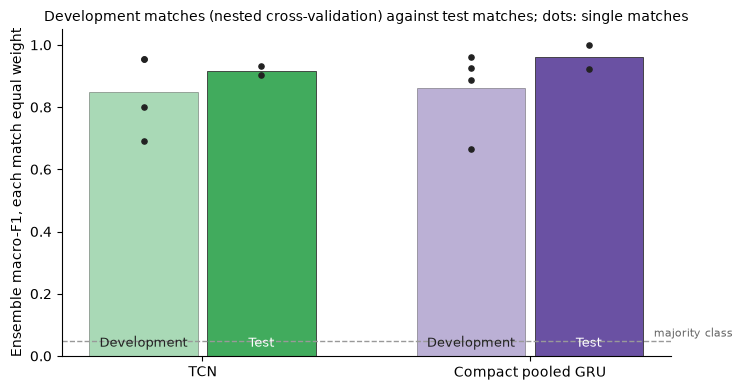

Both models scored higher on the test matches than on the development matches: the TCN 0.850 → 0.917, the GRU 0.860 → 0.962. Development scores varied widely between matches (TCN 0.690–0.956, GRU 0.665–0.962). Both test matches score in the upper half of that range or above it, and neither was as hard for the models as the hardest development match, Spirit vs Falcons; this is why the test averages are higher. With the ensemble and equal match weights, the GRU's development score is slightly above the TCN's; on the score used for selection, the TCN leads (0.849 against 0.792).

In [7]:
# @title Table and figure: development matches against test matches (ensemble, each match equal weight)
rows = [[MODEL[k], cv[k]["per_match_mean"], test[k]["per_match_mean"], test[k]["per_match_mean"] - cv[k]["per_match_mean"], f"{cv[k]['nested']:.3f} ± {cv[k]['nested_sd']:.3f}"] for k in KINDS]
show_table("cv-vs-test", pd.DataFrame(rows, columns=[
    "Model", f"Development: nested cross-validation ({len(TRAIN_MATCHES)} matches)", f"Test ({len(TEST_MATCHES)} matches)", "Test − development",
    "For reference: nested score used for selection (mean across three seeds ± SD)"]))

fig, ax = plt.subplots(figsize=(7.5, 4))
width = 0.36
for i, k in enumerate(KINDS):
    for j, (label, values, alpha) in enumerate([("Development", cv[k]["per_match"], 0.45), ("Test", test[k]["per_match"], 1.0)]):
        x = i + (j - 0.5) * width
        ax.bar(x, np.mean(list(values.values())), width * 0.92, color=COLOURS[k], alpha=alpha, edgecolor="#333", linewidth=0.6)
        ax.scatter([x] * len(values), list(values.values()), color="#222", s=14, zorder=3)
        ax.text(x, 0.02, label, ha="center", va="bottom", fontsize=9, color="white" if j else "#222")
ax.axhline(majority["per_match_mean"], color="#999", linestyle="--", linewidth=1)
ax.text(1.62, majority["per_match_mean"] + 0.015, "majority class", ha="right", fontsize=8, color="#666")
ax.set_xticks(range(len(KINDS)), [MODEL[k] for k in KINDS])
ax.set_ylim(0, 1.05)
ax.set_ylabel("Ensemble macro-F1, each match equal weight")
ax.set_title("Development matches (nested cross-validation) against test matches; dots: single matches", fontsize=10)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

spread = {k: (min(cv[k]["per_match"].values()), max(cv[k]["per_match"].values())) for k in KINDS}
hardest = min(cv["tcn"]["per_match"], key=cv["tcn"]["per_match"].get)
say(
    f"Both models scored higher on the test matches than on the development matches: the TCN {cv['tcn']['per_match_mean']:.3f} → {test['tcn']['per_match_mean']:.3f}, "
    f"the GRU {cv['gru']['per_match_mean']:.3f} → {test['gru']['per_match_mean']:.3f}. Development scores varied widely between matches "
    f"(TCN {spread['tcn'][0]:.3f}–{spread['tcn'][1]:.3f}, GRU {spread['gru'][0]:.3f}–{spread['gru'][1]:.3f}). Both test matches score in the upper half of that range or above it, "
    f"and neither was as hard for the models as the hardest development match, {MATCH_NAMES[hardest]}; this is why the test averages are higher. With the ensemble and equal match weights, the GRU's development score is slightly above the TCN's; "
    f"on the score used for selection, the TCN leads ({cv['tcn']['nested']:.3f} against {cv['gru']['nested']:.3f})."
)
claims("2.2 Development against test", [
    ("both models score higher on the test matches than in nested cross-validation (ensemble, each match equal weight)", lambda: all(test[k]["per_match_mean"] > cv[k]["per_match_mean"] for k in KINDS)),
    ("every test match scores in the upper half of the development range or above it", lambda: all(v >= sum(spread[k]) / 2 for k in KINDS for v in test[k]["per_match"].values())),
    ("the hardest development match is the same for both models, and every test match scores above it", lambda: all(min(cv[k]["per_match"], key=cv[k]["per_match"].get) == hardest for k in KINDS) and all(v > spread[k][0] for k in KINDS for v in test[k]["per_match"].values())),
    ("on this average the GRU's development score is slightly above the TCN's, while the TCN leads on the score used for selection", lambda: 0 < cv["gru"]["per_match_mean"] - cv["tcn"]["per_match_mean"] < 0.02 and cv["tcn"]["nested"] > cv["gru"]["nested"]),
])

## 3. Performance by tactic and match

Both tables use the ensemble predictions, as returned by the prediction API.

### 3.1 Which tactics did each model classify most accurately?

For each tactic, precision is the share of the model's predictions of that tactic that were right, and recall is the share of that tactic's clips the model found. Read them together: perfect recall with lower precision means the model found every clip of the tactic but also used it for clips of other tactics; perfect precision with lower recall means it was never wrong when it chose the tactic but missed some of its clips. F1 combines the two, and support is the number of test clips of the tactic.

In [8]:
# @title Table: precision, recall and F1 by tactic (ensemble)
rows = []
for c in CLASSES:
    tc, gc = test["tcn"]["ensemble"]["per_class"][c], test["gru"]["ensemble"]["per_class"][c]
    rows.append([c, tc["support"], tc["precision"], tc["recall"], tc["f1"], gc["precision"], gc["recall"], gc["f1"]])
show_table("per-tactic", pd.DataFrame(rows, columns=["Tactic", "Support", "TCN precision", "TCN recall", "TCN F1", "GRU precision", "GRU recall", "GRU F1"]))


def counted(labels):
    """['A_DIRECT', 'B_DIRECT'] -> 'one A_DIRECT and one B_DIRECT clip'; ['A_DIRECT'] * 2 -> 'two A_DIRECT clips'."""
    parts = [f"{WORDS[labels.count(c)]} {c}" for c in CLASSES if c in labels]
    return " and ".join(parts) + (" clips" if len(labels) > 1 and len(parts) == 1 else " clip")


def describe(k):
    """One sentence per tactic that is not perfect for model k, from its predictions."""
    out = []
    for i, c in enumerate(CLASSES):
        m = test[k]["ensemble"]["per_class"][c]
        if m["f1"] == 1.0:
            continue
        extra = [CLASSES[t] for t, p in zip(y, predicted[k]) if p == i and t != i]
        missed = [CLASSES[p] for t, p in zip(y, predicted[k]) if t == i and p != i]
        if m["recall"] == 1.0:
            out.append(f"found every {c} clip but also predicted {c} for {counted(extra)} (precision {m['precision']:.3f})")
        elif m["precision"] == 1.0:
            out.append(f"was right every time it predicted {c} but missed {counted([c] * len(missed))}, predicted as {' and '.join(sorted(set(missed)))} (recall {m['recall']:.3f})")
        else:
            out.append(f"missed {counted([c] * len(missed))} (predicted as {' and '.join(sorted(set(missed)))}) and predicted {c} for {counted(extra)} (F1 {m['f1']:.3f})")
    perfect = [c for c in CLASSES if test[k]["ensemble"]["per_class"][c]["f1"] == 1.0]
    return f"The {SHORT[k]} classified every {' and every '.join(perfect)} clip correctly with no false alarms; it " + "; it ".join(out) + "."


say(describe("tcn") + " " + describe("gru"))
f1 = {k: {c: test[k]["ensemble"]["per_class"][c]["f1"] for c in CLASSES} for k in KINDS}
recall = {k: {c: test[k]["ensemble"]["per_class"][c]["recall"] for c in CLASSES} for k in KINDS}
say(f"Both models have the same F1 on A_DIRECT ({f1['tcn']['A_DIRECT']:.3f}) and RETAKE ({f1['tcn']['RETAKE']:.3f}); they differ on the three smallest tactics, where a single clip moves F1 by a tenth or more.")
claims("3.1 By tactic", [
    ("both models find every A_SPLIT and every B_SPLIT clip", lambda: all(recall[k][c] == 1.0 for k in KINDS for c in ("A_SPLIT", "B_SPLIT"))),
    ("both models have the same F1 on A_DIRECT and on RETAKE", lambda: all(abs(f1["tcn"][c] - f1["gru"][c]) < TOLERANCE for c in ("A_DIRECT", "RETAKE"))),
    ("the models' F1 differs only on the three smallest tactics", lambda: {c for c in CLASSES if abs(f1["tcn"][c] - f1["gru"][c]) > TOLERANCE} == set(sorted(CLASSES, key=per_class_n.get)[:3])),
])

Tactic,Support,TCN precision,TCN recall,TCN F1,GRU precision,GRU recall,GRU F1
A_DIRECT,15,0.933,0.933,0.933,0.933,0.933,0.933
B_DIRECT,6,1.000,0.833,0.909,1.000,1.000,1.000
A_SPLIT,6,1.000,1.000,1.000,0.857,1.000,0.923
B_SPLIT,5,0.714,1.000,0.833,1.000,1.000,1.000
RETAKE,13,1.000,0.923,0.960,1.000,0.923,0.960


The TCN classified every A_SPLIT clip correctly with no false alarms; it missed one A_DIRECT clip (predicted as B_SPLIT) and predicted A_DIRECT for one RETAKE clip (F1 0.933); it was right every time it predicted B_DIRECT but missed one B_DIRECT clip, predicted as B_SPLIT (recall 0.833); it found every B_SPLIT clip but also predicted B_SPLIT for one A_DIRECT and one B_DIRECT clip (precision 0.714); it was right every time it predicted RETAKE but missed one RETAKE clip, predicted as A_DIRECT (recall 0.923). The GRU classified every B_DIRECT and every B_SPLIT clip correctly with no false alarms; it missed one A_DIRECT clip (predicted as A_SPLIT) and predicted A_DIRECT for one RETAKE clip (F1 0.933); it found every A_SPLIT clip but also predicted A_SPLIT for one A_DIRECT clip (precision 0.857); it was right every time it predicted RETAKE but missed one RETAKE clip, predicted as A_DIRECT (recall 0.923).

Both models have the same F1 on A_DIRECT (0.933) and RETAKE (0.960); they differ on the three smallest tactics, where a single clip moves F1 by a tenth or more.

### 3.2 How did performance vary between the two matches?

Each test match is scored on its own. With a little over twenty clips per match, one clip is several points of accuracy, so the table also counts the clips each model got right.

In [9]:
# @title Table: ensemble scores by test match
rows = []
for m in TEST_MATCHES:
    keep = matches == m
    rows.append([MATCH_NAMES[m], int(keep.sum()), test["tcn"]["per_match"][m], f"{int(right['tcn'][keep].sum())}/{int(keep.sum())}",
                 test["gru"]["per_match"][m], f"{int(right['gru'][keep].sum())}/{int(keep.sum())}"])
show_table("per-match", pd.DataFrame(rows, columns=["Match", "Clips", "TCN macro-F1", "TCN clips correct", "GRU macro-F1", "GRU clips correct"]))
navi, vit = TEST_MATCHES
wrong = {m: {k: int((~right[k] & (matches == m)).sum()) for k in KINDS} for m in TEST_MATCHES}
say(
    f"Both models did better on {MATCH_NAMES[navi]} than on {MATCH_NAMES[vit]}. On {MATCH_NAMES[navi]} the GRU classified every clip correctly and the TCN missed "
    f"{clips_word(wrong[navi]['tcn'])}; on {MATCH_NAMES[vit]} each model missed {clips_word(wrong[vit]['tcn'])}. "
    f"The gap between the models is therefore one clip, in {MATCH_NAMES[navi]}."
)
claims("3.2 By match", [
    ("both models score higher on NaVi vs Falcons than on Vitality vs Falcons", lambda: all(test[k]["per_match"][navi] > test[k]["per_match"][vit] for k in KINDS) and navi.startswith("navi")),
    ("the GRU gets every NaVi vs Falcons clip right and the TCN misses one", lambda: wrong[navi]["gru"] == 0 and wrong[navi]["tcn"] == 1),
    ("on Vitality vs Falcons both models miss the same number of clips", lambda: wrong[vit]["tcn"] == wrong[vit]["gru"] == 2),
])

Match,Clips,TCN macro-F1,TCN clips correct,GRU macro-F1,GRU clips correct
NaVi vs Falcons,24,0.931,23/24,1.000,24/24
Vitality vs Falcons,21,0.902,19/21,0.924,19/21


Both models did better on NaVi vs Falcons than on Vitality vs Falcons. On NaVi vs Falcons the GRU classified every clip correctly and the TCN missed one clip; on Vitality vs Falcons each model missed two clips. The gap between the models is therefore one clip, in NaVi vs Falcons.

## 4. Errors and agreement

### 4.1 Which tactics did the models confuse?

The confusion matrices count the test clips by true tactic (rows) and predicted tactic (columns) for each model's ensemble; the diagonal is correct. The table below them lists every clip that at least one model got wrong, with each model's answer and confidence as returned by the prediction API. A confidence below the API's threshold marks the answer as uncertain.

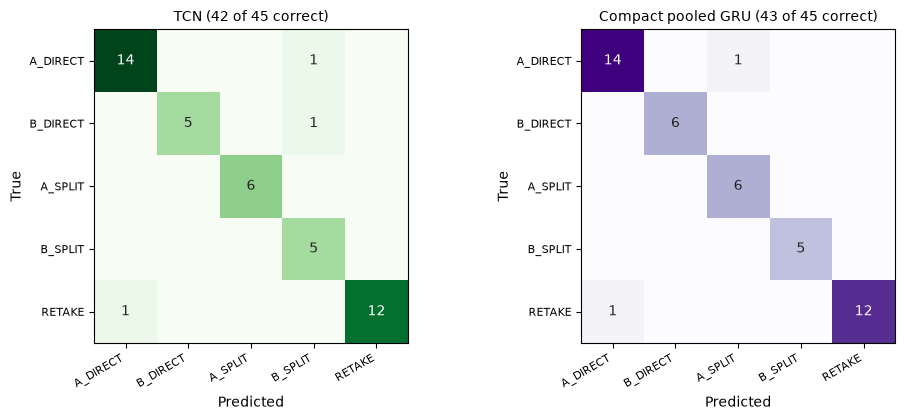

The TCN confused one clip of A_DIRECT as B_SPLIT; one clip of B_DIRECT as B_SPLIT; one clip of RETAKE as A_DIRECT. The GRU confused one clip of A_DIRECT as A_SPLIT; one clip of RETAKE as A_DIRECT. Each confusion involves a single clip.

In [10]:
# @title Figure: confusion matrices (ensemble, counts)
fig, axes = plt.subplots(1, 2, figsize=(10, 4.3))
for ax, k in zip(axes, KINDS):
    matrix = np.array(test[k]["ensemble"]["confusion"])
    ax.imshow(matrix, cmap="Greens" if k == "tcn" else "Purples", vmin=0, vmax=matrix.max())
    for i in range(len(CLASSES)):
        for j in range(len(CLASSES)):
            if matrix[i, j]:
                ax.text(j, i, matrix[i, j], ha="center", va="center", fontsize=10, color="white" if matrix[i, j] > matrix.max() / 2 else "#222")
    ax.set_xticks(range(len(CLASSES)), CLASSES, rotation=30, ha="right", fontsize=8)
    ax.set_yticks(range(len(CLASSES)), CLASSES, fontsize=8)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("True")
    ax.set_title(f"{MODEL[k]} ({int(np.trace(matrix))} of {matrix.sum()} correct)", fontsize=10)
plt.tight_layout()
plt.show()


def confusions(k):
    matrix = np.array(test[k]["ensemble"]["confusion"])
    return [f"{clips_word(int(matrix[i, j]))} of {CLASSES[i]} as {CLASSES[j]}" for i in range(len(CLASSES)) for j in range(len(CLASSES)) if i != j and matrix[i, j]]


say(f"The TCN confused {'; '.join(confusions('tcn'))}. The GRU confused {'; '.join(confusions('gru'))}. "
    "Each confusion involves a single clip.")

In [11]:
# @title Table: the clips at least one model got wrong
errors = [i for i, c in enumerate(clips) if not (right["tcn"][i] and right["gru"][i])]


def answer(c, k):
    a = by_app[c]["predictions"][k]
    return f"{a['tactic']} ({a['confidence']:.2f}{', uncertain' if a['uncertain'] else ''})"


show_table("errors", pd.DataFrame(
    [[short(clips[i]), MATCH_NAMES[matches[i]], CLASSES[y[i]], answer(clips[i], "tcn"), answer(clips[i], "gru")] for i in errors],
    columns=["Clip", "Match", "True", "TCN (confidence)", "GRU (confidence)"]))


def explain(i):
    c, a = clips[i], by_app[clips[i]]["predictions"]
    head = f"**{short(c)}** ({MATCH_NAMES[matches[i]]}, true {CLASSES[y[i]]}): "
    if a["tcn"]["tactic"] == a["gru"]["tactic"]:
        body = (f"both models answered {a['tcn']['tactic']}, the TCN with confidence {a['tcn']['confidence']:.2f}"
                f"{' (uncertain)' if a['tcn']['uncertain'] else ''} and the GRU with {a['gru']['confidence']:.2f}{' (uncertain)' if a['gru']['uncertain'] else ''}; "
                f"the TCN's second choice was {a['tcn']['runner_up']}.")
    else:
        parts_ = [f"the {SHORT[k]} answered {a[k]['tactic']} ({a[k]['confidence']:.2f}{', uncertain' if a[k]['uncertain'] else ''})" + (" and was right" if right[k][i] else "") for k in KINDS]
        body = "; ".join(parts_) + "."
    return head + body


say("\n\n".join(explain(i) for i in errors))
claims("4.1 Errors", [
    ("three clips were wrong for at least one model", lambda: len(errors) == 3),
    ("every confusion is a single clip", lambda: all(v <= 1 for k in KINDS for i, row in enumerate(test[k]["ensemble"]["confusion"]) for j, v in enumerate(row) if i != j)),
    ("every GRU error is also a TCN error", lambda: bool((~right["tcn"])[~right["gru"]].all())),
])

Clip,Match,True,TCN (confidence),GRU (confidence)
s022,NaVi vs Falcons,B_DIRECT,B_SPLIT (0.78),B_DIRECT (0.67)
s005,Vitality vs Falcons,RETAKE,"A_DIRECT (0.48, uncertain)",A_DIRECT (0.62)
s016,Vitality vs Falcons,A_DIRECT,"B_SPLIT (0.53, uncertain)","A_SPLIT (0.53, uncertain)"


**s022** (NaVi vs Falcons, true B_DIRECT): the TCN answered B_SPLIT (0.78); the GRU answered B_DIRECT (0.67) and was right.

**s005** (Vitality vs Falcons, true RETAKE): both models answered A_DIRECT, the TCN with confidence 0.48 (uncertain) and the GRU with 0.62; the TCN's second choice was RETAKE.

**s016** (Vitality vs Falcons, true A_DIRECT): the TCN answered B_SPLIT (0.53, uncertain); the GRU answered A_SPLIT (0.53, uncertain).

### 4.2 When did the second model give a different answer?

In the app the GRU is a second opinion, so the useful question is what a disagreement means. The table splits the test clips by whether the two models gave the same answer, and shows how often each was right in each group. The clips where they disagree are explained below it.

In [12]:
# @title Table: agreement between the two models (ensemble)
agree = predicted["tcn"] == predicted["gru"]
rows = [
    ["Same answer", int(agree.sum()), int((agree & right["tcn"]).sum()), int((agree & right["gru"]).sum())],
    ["Different answers", int((~agree).sum()), int((~agree & right["tcn"]).sum()), int((~agree & right["gru"]).sum())],
]
show_table("agreement", pd.DataFrame(rows, columns=["The two models give", "Clips", "TCN correct", "GRU correct"]))
differ = [i for i in range(len(clips)) if not agree[i]]
caught = int((~agree & ~right["tcn"]).sum())
say(
    f"The models gave the same answer on {int(agree.sum())} of {len(clips)} clips and were right on {int((agree & right['tcn']).sum())} of them. "
    f"They disagreed on {clips_word(len(differ))}:\n\n" + "\n\n".join(explain(i) for i in differ) + "\n\n"
    f"So a disagreement marked {WORDS[caught]} of the TCN's {WORDS[int((~right['tcn']).sum())]} errors; the remaining one was a clip both models got wrong in the same way."
)
claims("4.2 Agreement", [
    ("the models disagree on two clips", lambda: len(differ) == 2),
    ("when they agree they are right on all but one clip", lambda: int((agree & ~right["tcn"]).sum()) == 1),
    ("each disagreement is a TCN error, and the GRU is right on one of them", lambda: not right["tcn"][differ].any() and int(right["gru"][differ].sum()) == 1),
    ("a disagreement marks two of the TCN's three errors", lambda: caught == 2 and int((~right["tcn"]).sum()) == 3),
])

The two models give,Clips,TCN correct,GRU correct
Same answer,43,42,42
Different answers,2,0,1


The models gave the same answer on 43 of 45 clips and were right on 42 of them. They disagreed on two clips:

**s022** (NaVi vs Falcons, true B_DIRECT): the TCN answered B_SPLIT (0.78); the GRU answered B_DIRECT (0.67) and was right.

**s016** (Vitality vs Falcons, true A_DIRECT): the TCN answered B_SPLIT (0.53, uncertain); the GRU answered A_SPLIT (0.53, uncertain).

So a disagreement marked two of the TCN's three errors; the remaining one was a clip both models got wrong in the same way.

## 5. Limitations and conclusion

**Limitations.**

- **Small sample.** The test set has only two matches, and some tactics have very few clips in each. A one-clip change moves accuracy by a couple of points and a small tactic's F1 by about a tenth, so small differences between the models are not meaningful.
- **Team overlap.** Falcons play in both test matches and also in development matches, so the test is not a test on entirely unseen teams.
- **Previous TCN test exposure.** Earlier TCN experiments had already reported results on these matches during development, before the model comparison finished. The TCN's test result is therefore not a first look. The GRU was scored once, after the TCN had been selected.
- **Map regions.** The regions behind the shared clip features were designed using development labels only; no test clip shaped them.

In [13]:
# @title Conclusion
teams = lambda m: set(m.split("-mirage")[0].split("-"))
shared = set.intersection(*(teams(m) for m in TEST_MATCHES)) & set.union(*(teams(m) for m in TRAIN_MATCHES))
smallest_n = min(per_class_n.values())
say(
    f"In numbers: {len(clips)} test clips, so one clip is {1 / len(clips):.3f} of accuracy; the smallest tactic has {smallest_n} clips. "
    f"{', '.join(sorted(t.title() for t in shared))} play in both test matches and in {WORDS[sum('falcons' in teams(m) for m in TRAIN_MATCHES)]} of the {WORDS[len(TRAIN_MATCHES)]} development matches."
)
say(
    "**Conclusion.** The model was chosen on the development matches alone. The test adds an independent check on new matches: "
    f"the selected TCN keeps its development-level performance (ensemble, each match equal weight: {cv['tcn']['per_match_mean']:.3f} in development, "
    f"{test['tcn']['per_match_mean']:.3f} on test) and stays far above the majority-class baseline. "
    f"The Compact pooled GRU is as good on average across seeds ({test['gru']['mean']:.3f} against {test['tcn']['mean']:.3f}) and its ensemble was right on one more clip, "
    f"a one-clip difference that a two-match test cannot resolve; the test results do not change the choice. "
    f"As a second opinion, the GRU disagreed on {WORDS[caught]} of the TCN's {WORDS[int((~right['tcn']).sum())]} errors and never on a clip the TCN got right."
)
claims("5. Limitations and conclusion", [
    ("Falcons play in both test matches and in two development matches", lambda: shared == {"falcons"} and sum("falcons" in teams(m) for m in TRAIN_MATCHES) == 2),
    ("the test set has two matches and 45 clips; one clip is about two points of accuracy", lambda: len(TEST_MATCHES) == 2 and len(clips) == 45 and 0.015 < 1 / len(clips) < 0.025),
    ("some tactics have only five or six test clips", lambda: smallest_n in (5, 6)),
    ("the TCN's test score is at least its development score (ensemble, each match equal weight)", lambda: test["tcn"]["per_match_mean"] >= cv["tcn"]["per_match_mean"]),
    ("the two models' mean test macro-F1 across seeds differs by less than 0.01", lambda: abs(test["tcn"]["mean"] - test["gru"]["mean"]) < 0.01),
    ("the GRU never disagreed on a clip the TCN got right", lambda: not (~agree & right["tcn"]).any()),
])

In numbers: 45 test clips, so one clip is 0.022 of accuracy; the smallest tactic has 5 clips. Falcons play in both test matches and in two of the four development matches.

**Conclusion.** The model was chosen on the development matches alone. The test adds an independent check on new matches: the selected TCN keeps its development-level performance (ensemble, each match equal weight: 0.850 in development, 0.917 on test) and stays far above the majority-class baseline. The Compact pooled GRU is as good on average across seeds (0.890 against 0.897) and its ensemble was right on one more clip, a one-clip difference that a two-match test cannot resolve; the test results do not change the choice. As a second opinion, the GRU disagreed on two of the TCN's three errors and never on a clip the TCN got right.

## Appendix A. Reproducibility

### A1. Run folders

- **TCN:** `runs/tactic-tcn-clipdata-final`, made by `train-tactics --clip-data` on the 2026-11-16 export. Its `report.json` holds the test scores of each seed and of the ensemble; `predictions.csv` holds the ensemble's test predictions. Per-seed test predictions were not saved.
- **GRU:** `runs/tactic-gru-clipdata-final-20261121`, made by `train-gru-final` on the train-only copies ([guide](../docs/gru-predict.md)).
- **Test run:** `runs/tactic-gru-clipdata-test-20261121`, made once by `scripts/final_test_gru.py`. It computes the test clips' features once, as the prediction API does (one background per match, from that match's clips), checks that `predict_clips(models=("tcn",))` reproduces the TCN's saved test predictions, then runs `predict_clips(models=("gru",))` and each GRU seed on the same features. It trains and tunes nothing.
- **Development scores:** the nested cross-validation runs of the [comparison notebook](tactic-model-comparison.ipynb), `runs/tactic-tcn-clipdata-nested-20261120` and `runs/tactic-clipdata-nested-20261120`, on development matches only.

The notebook reads only these folders, which are tracked in Git; it needs neither the clips nor the dataset.

In [14]:
# @title Folders read
show_table("folders", pd.DataFrame([[key, path, "found"] for key, path in RUNS.items()], columns=["Role", "Folder", "Status"]))

Role,Folder,Status
tcn_final,runs/tactic-tcn-clipdata-final,found
gru_final,runs/tactic-gru-clipdata-final-20261121,found
gru_test,runs/tactic-gru-clipdata-test-20261121,found
tcn_nested,runs/tactic-tcn-clipdata-nested-20261120,found
gru_nested,runs/tactic-clipdata-nested-20261120,found


### A2. Scoring checks

Every score above is recomputed from the saved predictions when the notebook runs, and every statement in the text is checked against the data; a check that fails stops the notebook. The statements about earlier test exposure and the map regions come from the project's records and cannot be checked from these files.

In [15]:
# @title Checks that passed
say("\n".join(f"- **{section}:** " + "; ".join(items) + "." for section, items in CHECKS.items()))
say("**From the project's records (not checkable from these files):** earlier TCN experiments reported results on the test matches twice during development, "
    "before the comparison finished; the GRU was scored once, after selection; the map regions were designed using development labels only "
    "([clip data](../docs/clip-data.md#map-regions)).")

- **Saved scores:** the TCN's saved test predictions reproduce its saved test report (ensemble, per class, confusion, mean and SD across seeds); the prediction API (predict_clips) reproduced the TCN's saved test predictions on all 45 clips (largest probability difference 0.0000); the GRU's ensemble is the mean of its three seeds, and its saved report and the API's output match its predictions; both models scored the same 45 clips of 2 test matches, none of them a development match; the final TCN and GRU use the settings of their nested cross-validation runs, the same training clips and the same map regions; the nested cross-validation scores equal the saved summaries the comparison notebook reads.
- **Summary:** the test set has 45 clips from two matches; the counts of correct clips come from the ensemble predictions.
- **1. Evaluation setup:** both final models were trained on the same development clips with three seeds each; every test match has clips of every tactic.
- **2.1 Pooled test scores:** the two models' mean test macro-F1 across seeds differs by less than 0.01; the GRU's seeds vary more than the TCN's; the GRU's ensemble scores higher than the TCN's, by one clip; both models score far above the majority-class baseline.
- **2.2 Development against test:** both models score higher on the test matches than in nested cross-validation (ensemble, each match equal weight); every test match scores in the upper half of the development range or above it; the hardest development match is the same for both models, and every test match scores above it; on this average the GRU's development score is slightly above the TCN's, while the TCN leads on the score used for selection.
- **3.1 By tactic:** both models find every A_SPLIT and every B_SPLIT clip; both models have the same F1 on A_DIRECT and on RETAKE; the models' F1 differs only on the three smallest tactics.
- **3.2 By match:** both models score higher on NaVi vs Falcons than on Vitality vs Falcons; the GRU gets every NaVi vs Falcons clip right and the TCN misses one; on Vitality vs Falcons both models miss the same number of clips.
- **4.1 Errors:** three clips were wrong for at least one model; every confusion is a single clip; every GRU error is also a TCN error.
- **4.2 Agreement:** the models disagree on two clips; when they agree they are right on all but one clip; each disagreement is a TCN error, and the GRU is right on one of them; a disagreement marks two of the TCN's three errors.
- **5. Limitations and conclusion:** Falcons play in both test matches and in two development matches; the test set has two matches and 45 clips; one clip is about two points of accuracy; some tactics have only five or six test clips; the TCN's test score is at least its development score (ensemble, each match equal weight); the two models' mean test macro-F1 across seeds differs by less than 0.01; the GRU never disagreed on a clip the TCN got right.

**From the project's records (not checkable from these files):** earlier TCN experiments reported results on the test matches twice during development, before the comparison finished; the GRU was scored once, after selection; the map regions were designed using development labels only ([clip data](../docs/clip-data.md#map-regions)).

### A3. Environment and commands

In [16]:
# @title Environment
import platform

import matplotlib

say(f"Test manifest read by the test run: SHA-256 `{gru_test['test_manifest_sha256'][:16]}…`. "
    f"Notebook kernel: Python {platform.python_version()}; numpy {np.__version__}, pandas {pd.__version__}, matplotlib {matplotlib.__version__}.")

Test manifest read by the test run: SHA-256 `c50a94f484430d90…`. Notebook kernel: Python 3.13.15; numpy 2.2.6, pandas 3.0.6, matplotlib 3.11.2.

The test run was made once, from the repository root (PowerShell). Rerunning it needs the test clips and a new output folder; the notebook itself only reads the saved files.

```powershell
python scripts/final_test_gru.py --dataset data/processed/datasets/2026-11-16 --output runs/tactic-gru-clipdata-test-<new date>
```

To refresh this notebook's outputs without saving timing data, run it with nbclient and `record_timing=False`, or open it in Jupyter and run every cell from top to bottom.